
# Sesión 32 · Reducción de dimensionalidad y representación de variables

**Diplomado en Data Science UC — Facultad de Matemáticas**

Este notebook acompaña las slides de la Sesión 32 y continúa con lo que vimos en las sesiones anteriores:

- **Sesión 30** — preparación de datos (calidad, imputación, división train/val/test, Data Leakage).
- **Sesión 31** — introducción a Machine Learning (ciclo de aprendizaje, familias supervisado / no supervisado, y el cierre: *"cómo elegir, transformar y construir las variables que le damos a un modelo"*).

Usamos el caso de negocio que permite **predecir si un cliente de telco cancelará su suscripción (`fuga`)**. El notebook está dividido en 4 partes, igual que la presentación:

1. El problema de la alta dimensionalidad
2. Representación de variables (escalamiento, codificación, feature engineering)
3. Extracción de variables — **PCA**
4. **t-SNE**

> **Sobre los datos:** por defecto, este notebook trabaja con un dataset **sintético generado con una semilla fija**, para que a todos les salgan exactamente los mismos números y gráficos en clase, sin depender de subir ningún archivo.


## Preparación del entorno

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, matthews_corrcoef, classification_report

RANDOM_STATE = 32
np.random.seed(RANDOM_STATE)

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.25})



## 1. El problema de la alta dimensionalidad

Antes de tocar código, recordemos por qué nos importa esto (ver slides "Parte 1"):

- **Costo computacional**: más columnas → más tiempo de entrenamiento.
- **Multicolinealidad**: variables muy correlacionadas generan inestabilidad en regresiones y redes.
- **Variables ruido**: no todas las columnas aportan señal real.
- **Sesgo vs. varianza**: con pocas observaciones, más variables aumentan la varianza de las predicciones.




### 1.1 Carga de datos

In [ ]:

import os

# --------------------------------------------------------------------------
# USE_REAL_DATA = False (por defecto): usa el dataset SINTÉTICO con semilla
# fija (RANDOM_STATE = 32).
# --------------------------------------------------------------------------
USE_REAL_DATA = False


def generar_churn_sintetico(n=1500, seed=RANDOM_STATE):

    rng = np.random.default_rng(seed)

    insatisfaccion = rng.normal(0, 1, n)
    uso = rng.normal(0, 1, n)

    antiguedad = np.clip(rng.normal(24, 12, n), 1, 72).round(0)
    tipo_plan = rng.choice([1, 2], size=n, p=[0.55, 0.45])
    estado = rng.choice([1, 2], size=n, p=[0.85, 0.15])
    edad = np.clip(rng.normal(38, 12, n), 18, 80).round(0)

    numero_fallas = np.clip(6 + 4 * insatisfaccion + rng.normal(0, 2, n), 0, 35).round(0)
    reclamos = (rng.uniform(0, 1, n) < (0.05 + 0.12 * (insatisfaccion > 0.5))).astype(int)
    monto = np.clip((4 + 2 * uso + rng.normal(0, 1.5, n)).round(0), 0, 9)
    segundos = np.clip(4000 + 3000 * uso - 800 * insatisfaccion + rng.normal(0, 900, n), 50, None).round(0)
    frec_llamadas = np.clip((segundos / 65) + rng.normal(0, 8, n), 1, None).round(0)
    frec_sms = np.clip(60 + 90 * uso + rng.normal(0, 40, n), 0, None).round(0)
    n_contactos = np.clip((frec_llamadas * 0.35) + rng.normal(0, 5, n), 0, None).round(0)
    clv = np.clip(300 + 220 * uso - 90 * insatisfaccion + rng.normal(0, 120, n), 10, None).round(0)

    logit = (-2.2 + 0.9 * insatisfaccion + 0.05 * numero_fallas + 1.1 * reclamos
             - 0.02 * antiguedad - 0.15 * uso)
    prob_fuga = 1 / (1 + np.exp(-logit))
    fuga = (rng.uniform(0, 1, n) < prob_fuga).astype(int)

    return pd.DataFrame({
        "numero_fallas": numero_fallas, "reclamos": reclamos, "antiguedad": antiguedad,
        "monto": monto, "segundos": segundos, "frec_llamadas": frec_llamadas,
        "frec_sms": frec_sms, "n_contactos": n_contactos, "tipo_plan": tipo_plan,
        "estado": estado, "edad": edad, "clv": clv, "fuga": fuga,
    })


if USE_REAL_DATA and os.path.exists(RUTA_CHURN):
    df = pd.read_csv(RUTA_CHURN, sep=";", decimal=",", na_values=["", "NA", "NaN"])
    print(f"Cargado {RUTA_CHURN} con {df.shape[0]} filas y {df.shape[1]} columnas (datos reales).")
elif USE_REAL_DATA:
    df = generar_churn_sintetico()
    print(f"USE_REAL_DATA=True pero no se encontró '{RUTA_CHURN}' en esta carpeta.",
          "Se usó el dataset sintético con semilla fija como respaldo.")
else:
    df = generar_churn_sintetico()
    print(f"Dataset sintético generado con semilla fija (seed={RANDOM_STATE}):",
          f"{df.shape[0]} filas, {df.shape[1]} columnas.")

df.head()


Dataset sintético generado con semilla fija (seed=32): 1500 filas, 13 columnas.


,numero_fallas,reclamos,antiguedad,monto,segundos,frec_llamadas,frec_sms,n_contactos,tipo_plan,estado,edad,clv,fuga
0,8.0,0,21.0,3.0,3067.0,53.0,117.0,23.0,1,1,28.0,29.0,0
1,10.0,0,31.0,2.0,2544.0,31.0,77.0,9.0,1,2,30.0,235.0,0
2,6.0,0,13.0,4.0,6429.0,100.0,152.0,39.0,2,1,37.0,655.0,1
3,11.0,0,38.0,3.0,2113.0,39.0,9.0,17.0,2,1,44.0,246.0,0
4,4.0,0,24.0,2.0,4373.0,67.0,47.0,24.0,2,1,47.0,399.0,0



### 1.2 Limpieza rápida, estilo Sesión 30 (exactitud + completitud)

Antes de seguir, aplicamos las mismas reglas de calidad de datos de la Sesión 30: revisamos exactitud (valores físicamente imposibles) y completitud (datos faltantes), e imputamos siguiendo el criterio ya conocido (mediana para numéricas con atípicos, moda para binarias).

> Con el dataset sintético estas celdas normalmente no encuentran nada que corregir (los datos ya vienen limpios) — pero las dejamos igual, porque son exactamente las mismas que usarías si activas `USE_REAL_DATA = True`, donde sí podráin existir valores faltantes y algún error de captura.


In [ ]:

print("Nulos por columna antes de limpiar:")
print(df.isna().sum())

# Exactitud: 'edad' no debería ser negativa ni mayor a 100 años
n_invalidas = ((df["edad"] < 0) | (df["edad"] > 100)).sum()
print(f"\nValores de 'edad' fuera de rango físico: {n_invalidas}")
df.loc[(df["edad"] < 0) | (df["edad"] > 100), "edad"] = np.nan

# Completitud: imputación según el tipo de variable
for col in ["segundos", "frec_llamadas", "frec_sms", "n_contactos", "antiguedad", "edad"]:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())
if "reclamos" in df.columns:
    df["reclamos"] = df["reclamos"].fillna(df["reclamos"].mode()[0])

print("\nNulos restantes:", df.isna().sum().sum(), "(debería ser 0)")


Nulos por columna antes de limpiar:
numero_fallas    0
reclamos         0
antiguedad       0
monto            0
segundos         0
frec_llamadas    0
frec_sms         0
n_contactos      0
tipo_plan        0
estado           0
edad             0
clv              0
fuga             0
dtype: int64

Valores de 'edad' fuera de rango físico: 0

Nulos restantes: 0 (debería ser 0)


### 1.3 Panorama rápido: ¿cuántas variables, cuán correlacionadas?

In [ ]:

print(f"Observaciones: {df.shape[0]}  |  Variables (sin contar 'fuga'): {df.shape[1] - 1}")
print("\nTasa de fuga:")
print(df["fuga"].value_counts(normalize=True).rename("proporción"))


Observaciones: 1500  |  Variables (sin contar 'fuga'): 12

Tasa de fuga:
fuga
0    0.849333
1    0.150667
Name: proporción, dtype: float64


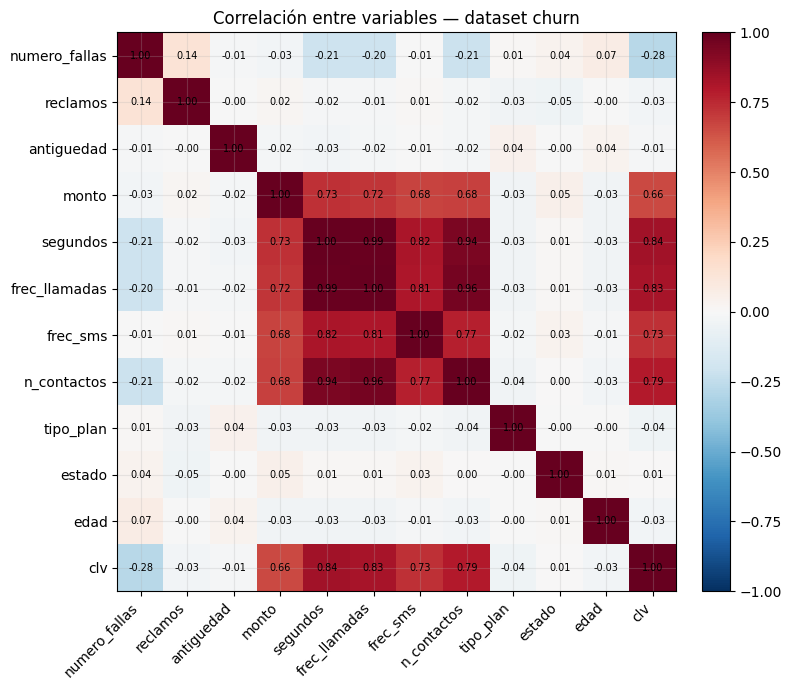

In [ ]:

X_raw = df.drop(columns=["fuga"])
y = df["fuga"]

corr = X_raw.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Correlación entre variables — dataset churn")
plt.tight_layout()
plt.show()



**Lectura:** varias variables de uso (`segundos`, `frec_llamadas`, `n_contactos`, `frec_sms`, `monto`, `clv`) están fuertemente correlacionadas entre sí. Esto es justamente la señal de que **hay redundancia** que PCA puede resumir: no necesitamos las 6 para decir "cuánto usa el cliente el servicio".



## 2. Representación de variables

Antes de reducir dimensionalidad, dejamos las variables en una forma que PCA y t-SNE puedan usar correctamente. Esto conecta directo con la Sesión 30 (calidad de datos) pero es un paso **distinto**: aquí no preguntamos "¿son correctos los datos?" sino "¿en qué forma se los entrego al modelo?".

### 2.1 Feature engineering — creamos variables nuevas antes de escalar


In [ ]:

X_fe = X_raw.copy()

# Variables construidas combinando columnas (ver slide "Creación de variables")
X_fe["duracion_prom_llamada"] = X_fe["segundos"] / X_fe["frec_llamadas"].replace(0, np.nan)
X_fe["sms_por_antiguedad"] = X_fe["frec_sms"] / X_fe["antiguedad"].replace(0, np.nan)
X_fe["intensidad_contacto"] = X_fe["n_contactos"] / X_fe["frec_llamadas"].replace(0, np.nan)

X_fe = X_fe.fillna(0)
X_fe[["duracion_prom_llamada", "sms_por_antiguedad", "intensidad_contacto"]].describe().T


,count,mean,std,min,25%,50%,75%,max
duracion_prom_llamada,1500.0,70.137203,83.399531,2.0,57.647527,63.538414,69.335938,2022.0
sms_por_antiguedad,1500.0,5.945325,15.568842,0.0,0.000000,2.584770,5.964286,226.0
intensidad_contacto,1500.0,0.478506,0.906719,0.0,0.291667,0.351064,0.407084,10.0



### 2.2 Codificación de variables categóricas

`tipo_plan` y `estado` ya vienen codificadas como enteros (1/2). Para modelos de árbol eso basta, pero PCA/t-SNE interpretan esos números como una **magnitud continua** (asumen que "2" está más lejos de "0" que de "1"), lo cual no tiene sentido para una categoría. Las convertimos a **one-hot**.


In [ ]:

categoricas = ["tipo_plan", "estado"]
numericas = [c for c in X_fe.columns if c not in categoricas]

encoder = OneHotEncoder(drop="if_binary", sparse_output=False)
cat_encoded = encoder.fit_transform(X_fe[categoricas].astype(str))
cat_cols = encoder.get_feature_names_out(categoricas)

X_encoded = pd.concat([
    X_fe[numericas].reset_index(drop=True),
    pd.DataFrame(cat_encoded, columns=cat_cols),
], axis=1)

print("Antes:", X_fe.shape[1], "columnas  →  Después de one-hot:", X_encoded.shape[1], "columnas")
X_encoded.head(3)


Antes: 15 columnas  →  Después de one-hot: 15 columnas


,numero_fallas,reclamos,antiguedad,monto,segundos,frec_llamadas,frec_sms,n_contactos,edad,clv,duracion_prom_llamada,sms_por_antiguedad,intensidad_contacto,tipo_plan_2,estado_2
0,8.0,0,21.0,3.0,3067.0,53.0,117.0,23.0,28.0,29.0,57.867925,5.571429,0.433962,0.0,0.0
1,10.0,0,31.0,2.0,2544.0,31.0,77.0,9.0,30.0,235.0,82.064516,2.483871,0.290323,0.0,1.0
2,6.0,0,13.0,4.0,6429.0,100.0,152.0,39.0,37.0,655.0,64.290000,11.692308,0.390000,1.0,0.0



### 2.3 División train/test **antes** de escalar (evitar Data Leakage, Sesión 30)

El escalador se ajusta (`fit`) solo con entrenamiento — igual que cualquier imputación o transformación — y luego se aplica (`transform`) a validación/prueba.


In [ ]:

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (1125, 15)  Test: (375, 15)



## 3. Extracción de variables — PCA

### 3.1 La base matemática, en código

Antes de usar `sklearn`, reproducimos el ejemplo de la slide con `numpy` puro: vectores y valores propios de una matriz.


In [ ]:

A = np.array([[10, -18],
              [6, -11]])

valores_propios, vectores_propios = np.linalg.eig(A)
print("Valores propios:", valores_propios)
print("Vectores propios (columnas):\n", vectores_propios)

# Verificación: A @ v == c * v  para el primer vector propio
v = vectores_propios[:, 0]
c = valores_propios[0]
print("\nA @ v      =", A @ v)
print("c * v      =", c * v)
print("¿Coinciden? ->", np.allclose(A @ v, c * v))


Valores propios: [ 1. -2.]
Vectores propios (columnas):
 [[0.89442719 0.83205029]
 [0.4472136  0.5547002 ]]

A @ v      = [0.89442719 0.4472136 ]
c * v      = [0.89442719 0.4472136 ]
¿Coinciden? -> True


### 3.2 PCA sobre el dataset completo (variables ya escaladas y codificadas)

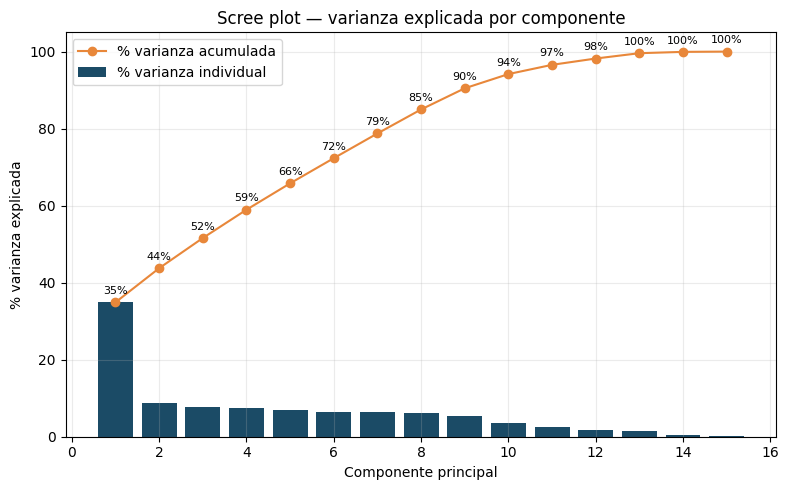

Con 8 componentes cubrimos al menos el 80% de la varianza total.


In [ ]:

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train)

var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

fig, ax = plt.subplots(figsize=(8, 5))
comps = np.arange(1, len(var_exp) + 1)
ax.bar(comps, var_exp * 100, color="#1B4B66", label="% varianza individual")
ax.plot(comps, var_acum * 100, color="#E8873A", marker="o", label="% varianza acumulada")
for x, yv in zip(comps, var_acum * 100):
    ax.annotate(f"{yv:.0f}%", (x, yv), textcoords="offset points", xytext=(0, 6), fontsize=8, ha="center")
ax.set_xlabel("Componente principal"); ax.set_ylabel("% varianza explicada")
ax.set_title("Scree plot — varianza explicada por componente")
ax.legend()
plt.tight_layout()
plt.show()

n_para_80 = int(np.argmax(var_acum >= 0.80) + 1)
print(f"Con {n_para_80} componentes cubrimos al menos el 80% de la varianza total.")



### 3.3 ¿Qué variables arma cada componente? (círculo de correlaciones)

El "círculo de correlaciones" grafica, para las 2 primeras componentes, cuánto pesa cada variable original. Flechas largas y cercanas al borde del círculo = esa variable está muy bien representada por PC1/PC2.


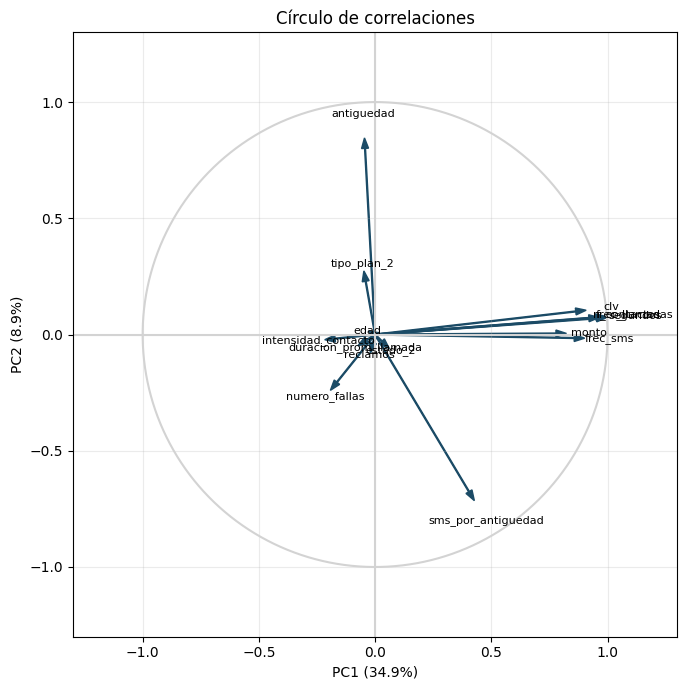

In [ ]:

def circulo_correlaciones(pca, columnas, comp_x=0, comp_y=1, figsize=(7, 7)):
    loadings = pca.components_[[comp_x, comp_y], :].T * np.sqrt(pca.explained_variance_[[comp_x, comp_y]])
    scale = 1.0 / np.max(np.linalg.norm(loadings, axis=1))

    fig, ax = plt.subplots(figsize=figsize)
    theta = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(theta), np.sin(theta), color="lightgray")
    ax.axhline(0, color="lightgray"); ax.axvline(0, color="lightgray")
    for i, col in enumerate(columnas):
        vx, vy = loadings[i] * scale
        ax.arrow(0, 0, vx, vy, color="#1B4B66", width=0.004, head_width=0.03, length_includes_head=True)
        ax.text(vx * 1.12, vy * 1.12, col, fontsize=8, ha="center", va="center")
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
    ax.set_xlabel(f"PC{comp_x+1} ({pca.explained_variance_ratio_[comp_x]*100:.1f}%)")
    ax.set_ylabel(f"PC{comp_y+1} ({pca.explained_variance_ratio_[comp_y]*100:.1f}%)")
    ax.set_title("Círculo de correlaciones")
    plt.tight_layout()
    plt.show()

circulo_correlaciones(pca_full, X_encoded.columns)


### 3.4 Proyectando clientes en las 2 primeras componentes, coloreados por fuga

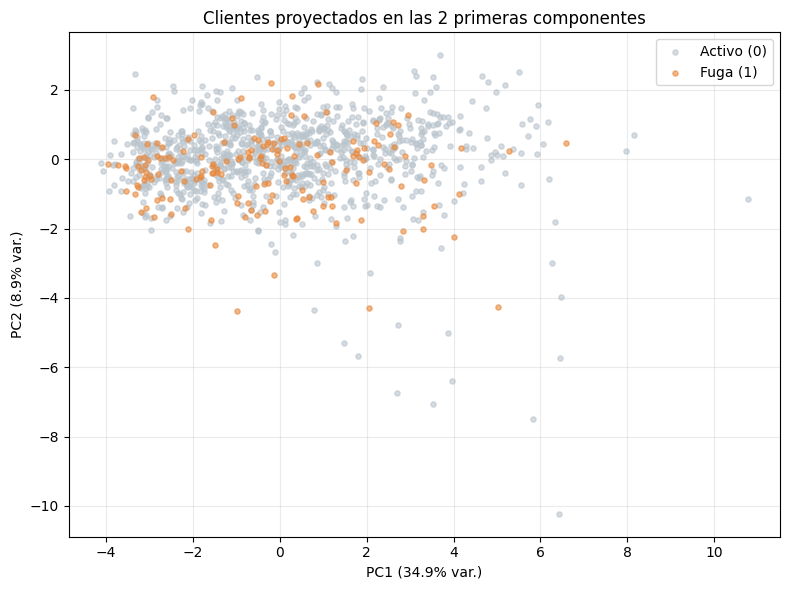

In [ ]:

pcs_train = pca_full.transform(X_train)

fig, ax = plt.subplots(figsize=(8, 6))
for val, color, label in [(0, "#B9C4CC", "Activo (0)"), (1, "#E8873A", "Fuga (1)")]:
    mask = y_train.values == val
    ax.scatter(pcs_train[mask, 0], pcs_train[mask, 1], s=14, alpha=0.6, color=color, label=label)
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.1f}% var.)")
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.1f}% var.)")
ax.set_title("Clientes proyectados en las 2 primeras componentes")
ax.legend()
plt.tight_layout()
plt.show()



### 3.5 ¿Reducir dimensiones cuesta desempeño?

Comparamos una regresión logística simple entrenada con **todas las variables** (ya escaladas/codificadas) vs. con solo los **componentes principales** necesarios para el 80% de la varianza.


In [ ]:

pca_k = PCA(n_components=n_para_80, random_state=RANDOM_STATE)
X_train_pca = pca_k.fit_transform(X_train)
X_test_pca = pca_k.transform(X_test)

resultados = {}
for nombre, (xtr, xte) in {
    f"Variables originales ({X_train.shape[1]})": (X_train, X_test),
    f"PCA ({n_para_80} componentes)": (X_train_pca, X_test_pca),
}.items():
    clf = LogisticRegression(max_iter=1000)
    clf.fit(xtr, y_train)
    pred = clf.predict(xte)
    resultados[nombre] = {
        "n_variables": xtr.shape[1],
        "f1": round(f1_score(y_test, pred), 3),
        "mcc": round(matthews_corrcoef(y_test, pred), 3),
    }

pd.DataFrame(resultados).T


,n_variables,f1,mcc
Variables originales (15),15.0,0.270,0.265
PCA (8 componentes),8.0,0.267,0.252



**Lectura (Sesión 30, "más allá del Accuracy"):** si F1 y MCC se mantienen similares con muchas menos columnas, PCA está haciendo su trabajo: concentró la señal y descartó redundancia, sin perder poder predictivo relevante.



## 4. t-SNE

t-SNE no busca conservar la varianza total (como PCA) sino las **relaciones de vecindad**: quiénes son "parecidos" entre sí. Es una técnica pensada para **visualizar**, no para producir variables reutilizables en un pipeline de producción.

Probamos distintos valores de `perplexity` (recuerda: debe ser menor al número de observaciones; rango típico 5–50).


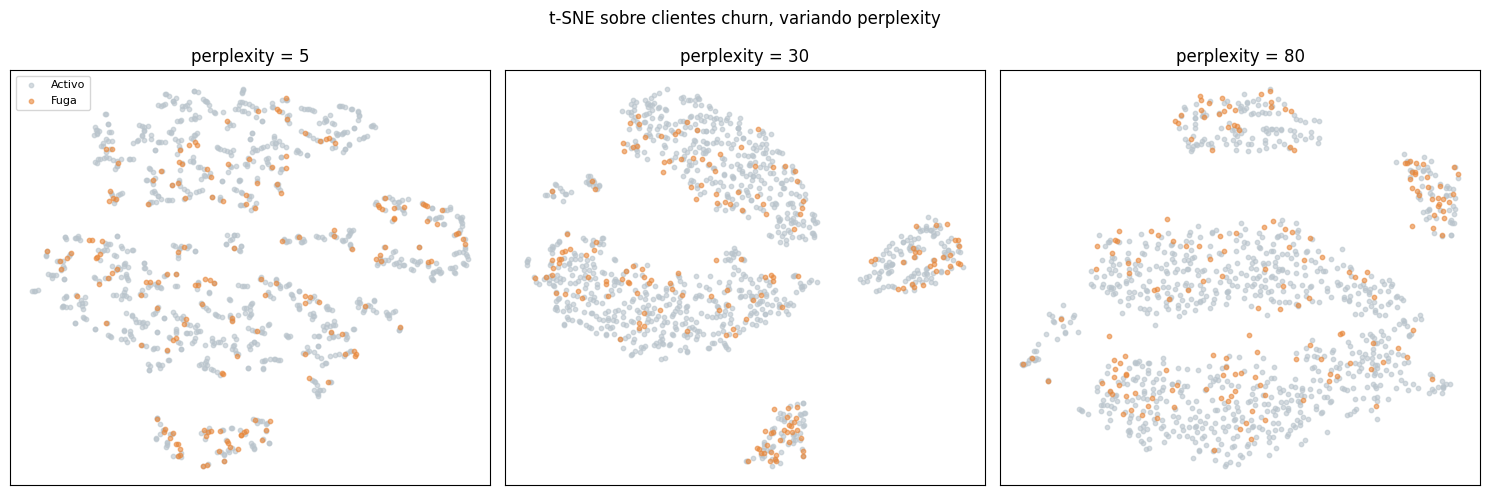

In [ ]:

perplexities = [5, 30, 80]
fig, axes = plt.subplots(1, len(perplexities), figsize=(15, 5))

for ax, perp in zip(axes, perplexities):
    tsne = TSNE(n_components=2, perplexity=perp, init="pca",
                learning_rate="auto", random_state=RANDOM_STATE)
    emb = tsne.fit_transform(X_train)
    for val, color, label in [(0, "#B9C4CC", "Activo"), (1, "#E8873A", "Fuga")]:
        mask = y_train.values == val
        ax.scatter(emb[mask, 0], emb[mask, 1], s=10, alpha=0.6, color=color, label=label)
    ax.set_title(f"perplexity = {perp}")
    ax.set_xticks([]); ax.set_yticks([])

axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("t-SNE sobre clientes churn, variando perplexity")
plt.tight_layout()
plt.show()



**Para experimentar en clase:**
- Baja el `perplexity` a 5 → se forman muchos grupos pequeños y locales.
- Súbelo a 80 → la estructura se ve más "global" y continua.
- Cambia `random_state` y compara: recuerda que t-SNE **no es determinístico**.



## 5. PCA vs. t-SNE — síntesis

| | PCA | t-SNE |
|---|---|---|
| Naturaleza | Lineal | No lineal |
| Qué conserva | Varianza global | Relaciones de vecindad local |
| Determinístico | Sí | No |
| Costo | Bajo | Alto (crece rápido con n) |
| ¿Sirve para nuevos datos? | Sí (`.transform()`) | No directamente — no está pensado para producción |
| Uso típico | Reducir antes de modelar | Explorar / visualizar estructura |

## 6. Para seguir practicando

1. Prueba agregar/quitar variables de `X_fe` (feature engineering) y observa cómo cambia el scree plot.
2. Compara el desempeño de un `RandomForestClassifier` con y sin PCA (¿es igual de sensible que la regresión logística?).
3. Con tu propio dataset, decide: ¿seleccionarías variables (Camino 1) o las extraerías con PCA (Camino 2)? Justifica con el círculo de correlaciones.

